# 06 · Error analysis

**Question:** where and why does the best classical model from notebook 05 fail, and does it lean on
anything it should not (the recording format, a baby's sex or age)?

Everything here reads the saved out-of-fold predictions and tuning choices of notebook 05. Nothing is
re-tuned. The one refit, for permutation importance, uses exactly the settings chosen in each outer
split and is checked against the saved predictions.

1. Confusions and per-class results
2. Grouped permutation importance: which feature groups the model actually uses
3. Calibration: are the probabilities honest, and does confidence separate right from wrong?
4. Per-baby results, and sex and age codes
5. The residual format check declared in notebook 03
6. The most confident mistakes, to listen to

In [1]:
import ast
import os
import sys
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")   # see notebook 05

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src import viz
from src.audio import CLASSES, load_clean_index
from src.features import BAND, feature_table, group_of
from src.metrics import balanced_accuracy, confusion, encode, log_loss, per_class_table
from src.models import class_prior, corrected, fit, predict_proba
from src.splits import PROBA_COLS, load_folds, load_predictions, outer_splits, repeats

viz.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)
idx = load_clean_index()
folds = load_folds(idx)
X = feature_table(BAND)
y, groups, t = idx["label"].to_numpy(), idx["source"].to_numpy(), encode(idx["label"])
RESULTS = REPO / "results"

ml = pd.read_csv(RESULTS / "ml_scores.csv")
ml = ml[ml["features"] == "band-limited, all groups"]
best = ml.loc[ml["balanced_accuracy"].idxmax()]
NAME, VARIANT = best["model"], best["variant"]
pred = load_predictions(f"ml_{NAME}_{VARIANT}", idx)
tuning = pd.read_csv(RESULTS / "ml_tuning.csv")
tuning = tuning[(tuning["model"] == NAME) & (tuning["variant"] == VARIANT)]
print(f"best model from notebook 05: {NAME} ({VARIANT}), balanced accuracy {best['balanced_accuracy']:.3f} "
      f"(95% CI {best['balanced_accuracy_low']:.3f}-{best['balanced_accuracy_high']:.3f})")
print(f"{len(pred)} out-of-fold predictions = {len(idx)} clips x {pred['repeat'].nunique()} repeats")

best model from notebook 05: random_forest (argmax), balanced accuracy 0.131 (95% CI 0.123-0.152)
2395 out-of-fold predictions = 479 clips x 5 repeats


## 1. Confusions

Counts are averaged over the 5 repeats, so each row adds up to the class's clip count. Colour is the
row share: where each class's clips end up.

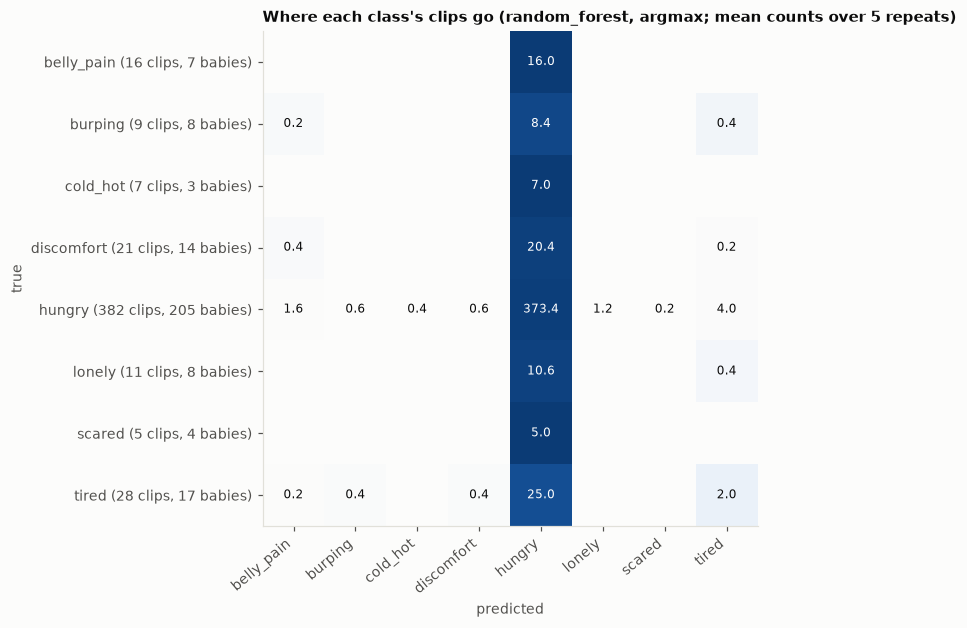

share of each class's clips predicted as hungry:
belly_pain    1.000
burping       0.933
cold_hot      1.000
discomfort    0.971
hungry        0.977
lonely        0.964
scared        1.000
tired         0.893


In [2]:
cm = sum(confusion(encode(g["y_true"]), encode(g["y_pred"])) for _, g in pred.groupby("repeat")) / pred["repeat"].nunique()
share = cm / cm.sum(axis=1, keepdims=True)
babies = idx.groupby("label")["source"].nunique()

fig, ax = plt.subplots(figsize=(7, 5.6), constrained_layout=True)
ax.imshow(share, cmap=viz.SPEC_CMAP, vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if share[i, j] > 0.55 else viz.INK)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=40, ha="right")
clips = idx["label"].value_counts()
ax.set_yticks(range(len(CLASSES)), [f"{c} ({clips[c]} clips, {babies[c]} babies)" for c in CLASSES])
ax.grid(False)
ax.set(xlabel="predicted", ylabel="true",
       title=f"Where each class's clips go ({NAME}, {VARIANT}; mean counts over 5 repeats)")
plt.show()

print("share of each class's clips predicted as hungry:")
print(pd.Series(share[:, CLASSES.index("hungry")], index=CLASSES).round(3).to_string())

In [3]:
tables = [per_class_table(encode(g.sort_values("clip")["y_true"]), encode(g.sort_values("clip")["y_pred"]), groups)
          for _, g in pred.groupby("repeat")]
per_class = pd.concat([tbl[["predicted", "precision", "recall", "f1"]] for tbl in tables]).groupby(level=0, sort=False).mean()
per_class.insert(0, "babies", tables[0]["babies"])
per_class.insert(0, "clips", tables[0]["clips"])
per_class["reliable (5+ babies)"] = tables[0]["reliable"]
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = (pd.DataFrame(off, index=CLASSES, columns=CLASSES).stack().rename("clips per repeat")
         .loc[lambda s: s > 0].sort_values(ascending=False).head(8))
pairs.index.names = ["true", "predicted"]
display(per_class.round(3))
print("most frequent confusions (true -> predicted):")
pairs.round(1)

,clips,babies,predicted,precision,recall,f1,reliable (5+ babies)
belly_pain,16,7,2.4,0.000,0.000,0.000,True
burping,9,8,1.0,0.000,0.000,0.000,True
cold_hot,7,3,0.4,0.000,0.000,0.000,False
discomfort,21,14,1.0,0.000,0.000,0.000,True
hungry,382,205,465.8,0.802,0.977,0.881,True
lonely,11,8,1.2,0.000,0.000,0.000,True
scared,5,4,0.2,0.000,0.000,0.000,False
tired,28,17,7.0,0.334,0.071,0.116,True


most frequent confusions (true -> predicted):


true        predicted
tired       hungry       25.0
discomfort  hungry       20.4
belly_pain  hungry       16.0
lonely      hungry       10.6
burping     hungry        8.4
cold_hot    hungry        7.0
scared      hungry        5.0
hungry      tired         4.0
Name: clips per repeat, dtype: float64

## 2. Which feature groups does the model use?

**Grouped permutation importance.** In every outer split, the model is refitted with the settings that
split chose in notebook 05. Then the columns of one feature group are shuffled *together* across the
test clips (5 shuffles), which breaks the group's link to the label while keeping its internal
structure. The drop in balanced accuracy, and the rise in log-loss, show how much the predictions
depend on that group. Because balanced accuracy is near chance, the log-loss change is the more
sensitive of the two. Values are means over shuffles, then mean ± std over the 5 repeats.

Groups: A log-mel band means and spread, B MFCC with deltas, C spectral shape, D pitch and voicing,
E rhythm (bursts and pauses), F energy dynamics.

In [4]:
GROUPS = sorted({group_of(c) for c in X.columns})
cols = {g: [i for i, c in enumerate(X.columns) if group_of(c) == g] for g in GROUPS}
Xv = X.to_numpy(dtype=float)
N_SHUFFLES = 5
rows, refit = [], []
for r in repeats(folds):
    for k, train, test in outer_splits(folds, r):
        choice = tuning[(tuning["repeat"] == r) & (tuning["fold"] == k)].iloc[0]
        params, tau = ast.literal_eval(choice["params"]), choice["tau"]
        model, p_train = fit(NAME, params, Xv[train], y[train]), class_prior(y[train])
        base = predict_proba(model, Xv[test])
        refit.append(pd.DataFrame({"clip": test, "repeat": r, "y_pred": np.array(CLASSES)[corrected(base, p_train, tau)]}))
        rng = np.random.default_rng(1000 * int(r[1:]) + k)
        for g in ["none"] + GROUPS:
            for s in range(N_SHUFFLES if g != "none" else 1):
                Xp = Xv[test].copy()
                if g != "none":
                    Xp[:, cols[g]] = Xp[rng.permutation(len(test))][:, cols[g]]
                proba = base if g == "none" else predict_proba(model, Xp)
                rows.append(pd.DataFrame({"repeat": r, "group": g, "shuffle": s, "clip": test,
                                          "code": corrected(proba, p_train, tau), "p_true": proba[np.arange(len(test)), t[test]]}))
perm = pd.concat(rows, ignore_index=True)

refit = pd.concat(refit).merge(pred[["clip", "repeat", "y_pred"]], on=["clip", "repeat"], suffixes=("_refit", "_saved"))
print(f"refitted predictions identical to notebook 05's: {(refit['y_pred_refit'] == refit['y_pred_saved']).mean():.1%} of {len(refit)}")

score = (perm.groupby(["repeat", "group", "shuffle"])
         .apply(lambda d: pd.Series({"ba": balanced_accuracy(t[d["clip"]], d["code"]),
                                     "ll": -np.mean(np.log(np.clip(d["p_true"], 1e-15, 1)))}), include_groups=False)
         .groupby(["repeat", "group"]).mean())
base = score.xs("none", level="group")
drop = pd.DataFrame({"BA drop": base["ba"] - score["ba"], "log-loss rise": score["ll"] - base["ll"]}).drop(index="none", level="group")
importance = drop.groupby("group").agg(["mean", "std"])
importance.insert(0, "features", [len(cols[g]) for g in importance.index])
importance.round(4)

refitted predictions identical to notebook 05's: 100.0% of 2395


features BA drop         log-loss rise        
                  mean     std          mean     std
group                                               
A           80  0.0033  0.0047       -0.0429  0.0702
B          120  0.0063  0.0045        0.0140  0.0949
C           10 -0.0000  0.0012       -0.0205  0.0174
D            6  0.0009  0.0018       -0.0073  0.0101
E            5 -0.0009  0.0020        0.0008  0.0082
F            4  0.0003  0.0007       -0.0023  0.0065

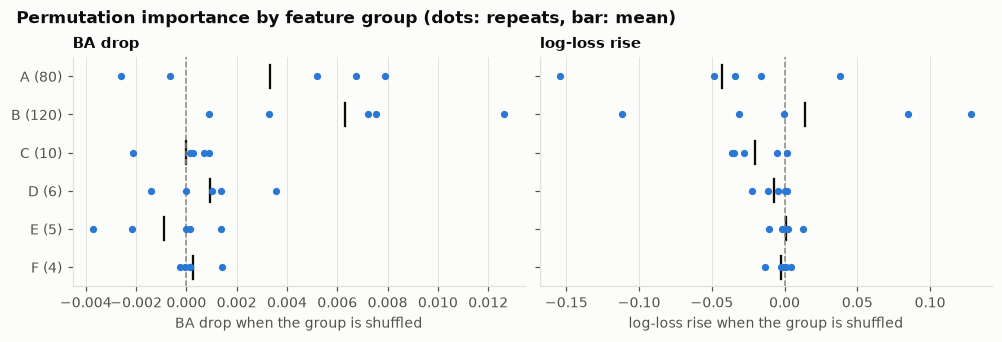

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), constrained_layout=True, sharey=True)
for ax, m in zip(axes, ["BA drop", "log-loss rise"]):
    per_rep = drop[m].unstack("group")
    for i, g in enumerate(GROUPS):
        ax.scatter(per_rep[g], np.full(len(per_rep), i), color=viz.BLUE, s=14, zorder=3)
        ax.plot([per_rep[g].mean()] * 2, [i - 0.3, i + 0.3], color=viz.INK, lw=1.5)
    ax.axvline(0, color=viz.GREY, lw=1, ls="--")
    ax.set_yticks(range(len(GROUPS)), [f"{g} ({len(cols[g])})" for g in GROUPS])
    ax.set_ylim(len(GROUPS) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set(xlabel=f"{m} when the group is shuffled", title=m)
fig.suptitle("Permutation importance by feature group (dots: repeats, bar: mean)", x=0.01, ha="left", fontweight="bold")
plt.show()

## 3. Calibration

Two questions. Are the probabilities honest: when the model says 0.8, is it right 80% of the time?
And does its confidence carry information: are correct predictions made with more confidence than
wrong ones (AUROC of the confidence for right vs wrong, 0.5 = no information)?

Confidence is the probability of the predicted class. Bins hold equal numbers of predictions; all 5
repeats are pooled. The always-hungry baseline is the reference: its confidence is the training share
of *hungry*, about 0.8, and it is right 79.7% of the time.

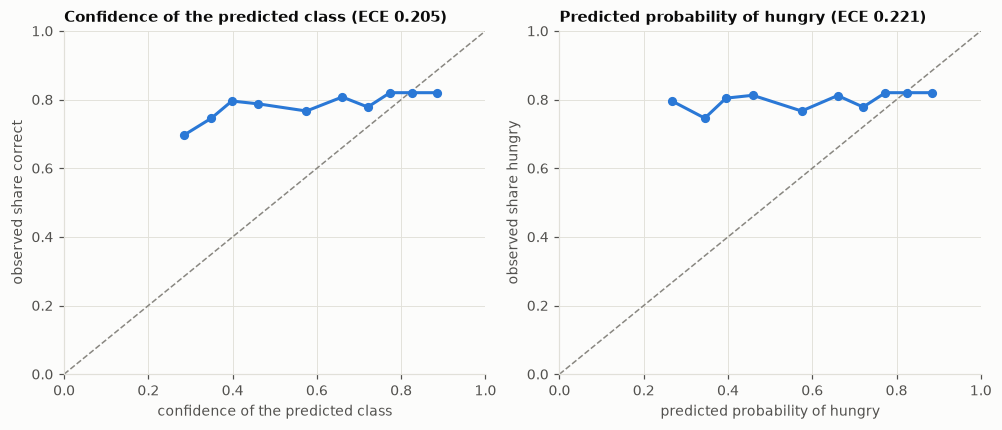

AUROC of confidence, right vs wrong: 0.549 ± 0.029 over repeats
mean confidence: 0.601 when right, 0.564 when wrong
log-loss 1.213 (always-hungry baseline, notebook 04: 0.887)


In [6]:
P = pred[PROBA_COLS].to_numpy()
pred_code = encode(pred["y_pred"])
conf = P[np.arange(len(P)), pred_code]
right = (pred_code == encode(pred["y_true"])).astype(int)
p_hungry, is_hungry = pred["p_hungry"].to_numpy(), (pred["y_true"] == "hungry").to_numpy().astype(int)


def reliability(p, hit, n_bins=10):
    order = np.argsort(p, kind="stable")
    bins = np.array_split(order, n_bins)
    return np.array([p[b].mean() for b in bins]), np.array([hit[b].mean() for b in bins]), np.array([len(b) for b in bins])


fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
for ax, (p, hit, what) in zip(axes, [(conf, right, "confidence of the predicted class"),
                                     (p_hungry, is_hungry, "predicted probability of hungry")]):
    mp, mh, n = reliability(p, hit)
    ax.plot([0, 1], [0, 1], color=viz.GREY, lw=1, ls="--")
    ax.plot(mp, mh, color=viz.BLUE, marker="o", ms=5)
    ece = np.sum(n * np.abs(mp - mh)) / n.sum()
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel=what, ylabel="observed share correct" if ax is axes[0] else "observed share hungry",
           title=f"{what.capitalize()} (ECE {ece:.3f})")
plt.show()

auc_conf = pd.Series({r: roc_auc_score(right[g.index], conf[g.index]) for r, g in pred.groupby("repeat")})
print(f"AUROC of confidence, right vs wrong: {auc_conf.mean():.3f} ± {auc_conf.std(ddof=1):.3f} over repeats")
print(f"mean confidence: {conf[right == 1].mean():.3f} when right, {conf[right == 0].mean():.3f} when wrong")
print(f"log-loss {np.mean([log_loss(t[g['clip']], g[PROBA_COLS].to_numpy()) for _, g in pred.groupby('repeat')]):.3f} "
      f"(always-hungry baseline, notebook 04: 0.887)")

## 4. Per baby, and by sex and age code

A model that never saw a baby can still be right on it by predicting *hungry*. So babies are split by
what they contributed: only *hungry* clips, or at least one clip of another class. Sex and the age
code come from the file names (notebook 01). The meaning of the age codes is not documented in this
copy of the dataset, so they are shown as recorded. Subgroups differ in their mix of labels, so their
accuracies are not comparable without the label mix next to them.

In [7]:
clip_acc = (pred.assign(ok=pred["y_true"] == pred["y_pred"]).groupby("clip")["ok"].mean()
            .reindex(range(len(idx))))
per_baby = (idx.assign(acc=clip_acc.to_numpy(), minority=idx["label"] != "hungry")
            .groupby("source").agg(clips=("path", "size"), any_minority=("minority", "any"), accuracy=("acc", "mean")))
summary = per_baby.groupby("any_minority").agg(babies=("clips", "size"), clips=("clips", "sum"),
                                               mean_accuracy=("accuracy", "mean"),
                                               babies_never_right=("accuracy", lambda a: int((a == 0).sum())))
summary.index = summary.index.map({False: "only hungry clips", True: "at least one other class"})
display(summary.round(3))

def subgroup(col):
    d = idx.assign(acc=clip_acc.to_numpy())
    out = d.groupby(col).agg(clips=("path", "size"), babies=("source", "nunique"),
                             share_hungry=("label", lambda s: (s == "hungry").mean()),
                             accuracy=("acc", "mean"))
    out["recall on hungry"] = d[d["label"] == "hungry"].groupby(col)["acc"].mean()
    out["recall on other classes"] = d[d["label"] != "hungry"].groupby(col)["acc"].mean()
    out["other-class clips"] = d[d["label"] != "hungry"].groupby(col).size()
    return out

display(subgroup("gender").round(3))
display(subgroup("age_code").round(3))

# a "source" is an app install, normally one baby; some carry several labels, sexes or age codes
src = idx.groupby("source").agg(clips=("path", "size"), labels=("label", "nunique"),
                                sexes=("gender", "nunique"), age_codes=("age_code", "nunique"))
print(f"sources with more than one label: {(src['labels'] > 1).sum()} of {len(src)}; "
      f"with more than one sex or age code: {((src['sexes'] > 1) | (src['age_codes'] > 1)).sum()}")
src.sort_values(["labels", "clips"], ascending=False).head(3)

,babies,clips,mean_accuracy,babies_never_right
any_minority,,,,
only hungry clips,175,325,0.972,0
at least one other class,51,154,0.321,18


,clips,babies,share_hungry,accuracy,recall on hungry,recall on other classes,other-class clips
gender,,,,,,,
f,192,93,0.781,0.767,0.976,0.019,42
m,287,144,0.808,0.795,0.978,0.022,55


,clips,babies,share_hungry,accuracy,recall on hungry,recall on other classes,other-class clips
age_code,,,,,,,
04,154,85,0.864,0.838,0.970,0.000,21
22,10,9,0.900,0.900,1.000,0.000,1
26,171,76,0.760,0.767,0.994,0.049,41
48,55,26,0.764,0.731,0.957,0.000,13
72,89,48,0.764,0.742,0.971,0.000,21


sources with more than one label: 31 of 226; with more than one sex or age code: 19


,clips,labels,sexes,age_codes
source,,,,
d6cda191-4962-4308-9a36-46d5648a95ed,15,6,2,3
999bf14b-e417-4b44-b746-9253f81efe38,11,4,1,2
1309b82c-f146-46f0-a723-45345afa6ea8,7,3,1,3


## 5. Residual format check (declared in notebook 03)

In this dataset, *cold_hot*, *lonely* and *scared* exist only as 44.1 kHz recordings, while *tired*,
*discomfort* and *burping* are mostly 8 kHz with a few 44.1 kHz clips. If the model had learnt "44.1 kHz
means cold_hot, lonely or scared", the 44.1 kHz clips of tired, discomfort and burping would get more
probability on those three classes than their 8 kHz clips do. Notebook 03 showed that a detector *could*
pick up the format (AUROC 0.82 band-limited). This checks whether the class model *does*.

Score: probability on cold_hot + lonely + scared, averaged over the 5 repeats. AUROC 0.5 means no format effect.

In [8]:
three = ["p_cold_hot", "p_lonely", "p_scared"]
p3 = pred.assign(p3=pred[three].sum(axis=1)).groupby("clip").agg(
    p3=("p3", "mean"), as_three=("y_pred", lambda s: s.isin(["cold_hot", "lonely", "scared"]).sum()))
check = idx.join(p3).loc[lambda d: d["label"].isin(["tired", "discomfort", "burping"])]
check["44.1 kHz"] = check["sample_rate"] == 44100
print(check.groupby("44.1 kHz").agg(clips=("path", "size"), babies=("source", "nunique"),
                                    mean_p3=("p3", "mean"), median_p3=("p3", "median"),
                                    predicted_as_one_of_the_three=("as_three", "sum")).round(4).to_string())
auc_fmt = roc_auc_score(check["44.1 kHz"], check["p3"])
ranks = check["p3"].rank(ascending=False)[check["44.1 kHz"]].sort_values().astype(int).tolist()
print(f"\nAUROC, 44.1 kHz vs 8 kHz clips of these classes: {auc_fmt:.2f}")
print(f"ranks of the {check['44.1 kHz'].sum()} 44.1 kHz clips among {len(check)} (1 = most cold_hot/lonely/scared-like): {ranks}")
p_mw = mannwhitneyu(check.loc[check["44.1 kHz"], "p3"], check.loc[~check["44.1 kHz"], "p3"], alternative="greater").pvalue
print(f"one-sided Mann-Whitney p = {p_mw:.3f} (treats clips as independent, which they are not)")

# three of the six clips come from one baby: drop each 44.1 kHz baby in turn
for baby in check.loc[check["44.1 kHz"], "source"].unique():
    keep = check[check["source"] != baby]
    print(f"  without baby {baby[:8]} ({(check['source'] == baby).sum()} clips): "
          f"AUROC {roc_auc_score(keep['44.1 kHz'], keep['p3']):.2f}")

          clips  babies  mean_p3  median_p3  predicted_as_one_of_the_three
44.1 kHz                                                                  
False        52      33   0.0811     0.0726                              0
True          6       4   0.1170     0.1056                              0

AUROC, 44.1 kHz vs 8 kHz clips of these classes: 0.81
ranks of the 6 44.1 kHz clips among 58 (1 = most cold_hot/lonely/scared-like): [3, 9, 13, 15, 20, 21]
one-sided Mann-Whitney p = 0.006 (treats clips as independent, which they are not)
  without baby efd13da0 (1 clips): AUROC 0.78
  without baby a40b9b8d (2 clips): AUROC 0.81
  without baby cecd525b (4 clips): AUROC 0.87
  without baby d2d67a70 (1 clips): AUROC 0.81


## 6. The most confident mistakes

Clips that are wrong in all 5 repeats, sorted by the mean probability given to the wrong class. The
paths are relative to the dataset folder, so these clips can be found and listened to. The second
table shows the mistakes the model makes when it predicts something *other* than hungry.

In [9]:
wrong = pred[pred["y_true"] != pred["y_pred"]].copy()
wrong["confidence"] = wrong[PROBA_COLS].to_numpy()[np.arange(len(wrong)), encode(wrong["y_pred"])]
per_clip = wrong.groupby("clip").agg(wrong_in=("repeat", "size"), predicted=("y_pred", lambda s: s.mode()[0]),
                                     confidence=("confidence", "mean"))
per_clip = idx[["path", "label", "sample_rate"]].join(per_clip, how="inner")
display(per_clip[per_clip["wrong_in"] == 5].sort_values("confidence", ascending=False).head(12).round(3))
other = (wrong[wrong["y_pred"] != "hungry"].groupby(["clip", "y_pred"]).agg(times=("repeat", "size"), confidence=("confidence", "mean"))
         .reset_index().join(idx[["path", "label"]], on="clip").sort_values(["times", "confidence"], ascending=False))
print(f"wrong non-hungry predictions: {len(wrong[wrong['y_pred'] != 'hungry'])} over 5 repeats; most repeated:")
other[["path", "label", "y_pred", "times", "confidence"]].head(12).round(3)

,path,label,sample_rate,wrong_in,predicted,confidence
468,tired/ca7d8d54-13cb-4060-8db4-90651b60c078-1434674792223-1.7-f-26-ti.wav,tired,8000,5,hungry,0.785
13,belly_pain/d6cda191-4962-4308-9a36-46d5648a95ed-1431159262344-1.7-m-04-bp.wav,belly_pain,8000,5,hungry,0.775
476,tired/d6cda191-4962-4308-9a36-46d5648a95ed-1431587899682-1.7-m-04-ti.wav,tired,8000,5,hungry,0.764
30,cold_hot/d6cda191-4962-4308-9a36-46d5648a95ed-1431086262776-1.7-m-04-ch.wav,cold_hot,44100,5,hungry,0.738
23,burping/af30880e-5f98-4dc0-b37a-be6b21fa0ba3-1431240072536-1.7-m-26-bu.wav,burping,8000,5,hungry,0.738
475,tired/d6cda191-4962-4308-9a36-46d5648a95ed-1431587887997-1.7-m-04-ti.wav,tired,8000,5,hungry,0.733
51,discomfort/d6cda191-4962-4308-9a36-46d5648a95ed-1431161889263-1.7-m-04-dc.wav,discomfort,8000,5,hungry,0.714
477,tired/d6cda191-4962-4308-9a36-46d5648a95ed-1431616581736-1.7-m-04-ti.wav,tired,8000,5,hungry,0.709
14,belly_pain/d6cda191-4962-4308-9a36-46d5648a95ed-1431159272600-1.7-m-04-bp.wav,belly_pain,8000,5,hungry,0.703
464,tired/C421C6FE-DFEE-4080-8AEA-848E7CE4756B-1430548393-1.0-f-26-ti.wav,tired,8000,5,hungry,0.690


wrong non-hungry predictions: 56 over 5 repeats; most repeated:


,path,label,y_pred,times,confidence
24,hungry/B327333E-2DE2-4833-A75A-4C576208BED3-1430087443-1.0-f-48-hu.wav,hungry,tired,5,0.496
10,hungry/415d69b4-6d84-4bf8-97b0-10f8f108dc1d-1430739498797-1.7-m-04-hu.wav,hungry,tired,3,0.335
12,hungry/415d69b4-6d84-4bf8-97b0-10f8f108dc1d-1430739528719-1.7-m-04-hu.wav,hungry,tired,3,0.301
0,burping/7A864194-4B6B-4850-ABBF-0C2A8170107B-1436846915-1.1-f-26-bu.wav,burping,tired,2,0.470
17,hungry/7e3de9b8-2be5-473f-b8c3-c2657f1317bb-1430006339251-1.7-f-04-hu.wav,hungry,cold_hot,2,0.470
33,lonely/076e33bf-c599-4eee-a6e3-dbc1986ee493-1437288944366-1.7-f-72-lo.wav,lonely,tired,2,0.338
27,hungry/CC8771B1-C84E-4223-A010-029A7629A975-1434107299-1.1-f-04-hu.wav,hungry,belly_pain,2,0.308
7,hungry/3d3e244d-20b1-4ec3-9732-92dcd14ff35a-1436961241219-1.7-m-72-hu.wav,hungry,tired,2,0.297
20,hungry/8f4dbf5a-b504-4452-b6ac-94e646a6a052-1430734962301-1.7-f-72-hu.wav,hungry,lonely,2,0.279
28,hungry/DBA77EDC-D457-4B3A-83B8-B7AFBF272D4E-1436860486-1.1-m-72-hu.wav,hungry,belly_pain,2,0.270


## 7. Findings

- **The model is an always-hungry classifier with small exceptions.** 89-100% of every other class's clips are
  predicted *hungry*. Only *tired* is ever predicted correctly, 2.0 of 28 clips per repeat, at the cost of 4.0 hungry clips per
  repeat predicted as tired. Seven of the eight most frequent confusions are "X predicted as hungry".
- **No feature group carries reliable information.** Shuffling MFCCs (B) lowers balanced accuracy by 0.006 ± 0.005 and
  log-mel bands (A) by 0.003 ± 0.005. Every other group changes it by at most 0.001. The log-loss changes are
  smaller than their spread across repeats: shuffling A even *lowers* log-loss on average (-0.043 ± 0.070).
- **The probabilities are under-confident, and confidence says little.** The predicted class gets probability of about 0.3-0.9,
  but the model is right 70-82% of the time across that whole range (ECE 0.205; 0.221 for the probability of hungry).
  Confidence barely separates right from wrong: AUROC 0.549 ± 0.029, mean confidence 0.601 when right vs 0.564 when
  wrong. Log-loss is 1.213, worse than the always-hungry baseline's 0.887.
- **Per baby:** the 175 babies with only hungry clips are predicted correctly 97.2% of the time. The 51 with any other
  class get 32.1%, and 18 of them are never right. Sex and age code make no visible difference: recall on non-hungry clips
  is 0.019 (f) vs 0.022 (m) and 0.000-0.049 across age codes.
- **Some "babies" are probably not one baby.** 31 of 226 sources have clips under more than one label, and 19 have more
  than one sex or age code. One source (d6cda191) has 15 clips under 6 labels, 2 sexes and 3 age codes, and accounts
  for 7 of the 12 most confident mistakes. It may be a shared or test install, or its labels may be noisy; the data cannot
  tell which.
- **The pre-declared format check is positive, in the probabilities only.** The six 44.1 kHz clips of tired, discomfort
  and burping get more probability on cold_hot + lonely + scared (the 44.1 kHz-only classes) than the 52 8 kHz clips of
  the same classes: mean 0.117 vs 0.081, AUROC 0.81 (0.78-0.87 leaving out each of the 4 babies in turn), ranks 3, 9, 13,
  15, 20 and 21 of 58. The one-sided Mann-Whitney p = 0.006 treats clips as independent, which they are not. The trace never
  changes a prediction (0 of these clips are predicted as one of the three), so it does not inflate notebook 05's
  scores. But band-limiting did not remove it, and the model does use it. Any model that predicts those three classes
  needs this check, including the CNN in notebook 07. It rests on 6 clips from 4 babies.